# **TP Big Data Wildlife Dataset**

## FAR Adam 5A Info FISE
## ID21

Le TP s'exécute de bout en bout, voici les contributions au notebook:


## Contributions au notebook



* **Étape 1 : DATA (Initialisation Spark & Chargement des données)**
  * Initialisation de la session Spark (`SparkSession`) avec une configuration mémoire optimisée.
  * Chargement des images binaires (`binaryFile`) pour les ensembles d'entraînement et de test.
  * Extraction automatique des étiquettes (`label_name`) à partir des chemins de fichiers.

* **Étape 2 : EDA (Exploratory Data Analysis)**
  * Analyse exploratoire distribuée pour vérifier la volumétrie, l'équilibre des classes d'animaux et la propreté du jeu de données.

* **Étape Intermédiaire : Préparation et Conversion du Dataset**
  * Conversion de la structure d'origine (format YOLO avec fichiers textes d'étiquettes) vers un format de classification standard (`ImageFolder`) à l'aide d'un traitement multithreadé (`ThreadPoolExecutor`).

* **Étape 3 : PRÉTRAITEMENT (Nettoyage & Extraction de caractéristiques)**
  * Utilisation d'une UDF (User Defined Function) Python pour ouvrir, redimensionner les images à **$32 \times 32$ pixels** (pour alléger la mémoire) et les convertir en vecteurs de pixels denses.

* **Étape 4 : TRANSFORMATION (Indexation, Normalisation & Cache)**
  * **`StringIndexer`** : Encodage des noms textuels des animaux en indices numériques (`0, 1, 2...`).
  * **`StandardScaler`** : Normalisation des vecteurs de pixels pour homogénéiser l'échelle des données.
  * **Mise en cache (`.cache()`)** : Stockage des données transformées en mémoire vive pour accélérer les calculs en aval.

* **Étape 5 : ML (Entraînement du modèle)**
  * Entraînement d'un classifieur distribué de type Forêt Aléatoire (`RandomForestClassifier`) sur les caractéristiques visuelles.

* **Étape 6 : EVAL (Évaluation des performances)**
  * Prédiction sur le jeu de test et calcul des métriques de référence (`Accuracy` et score `F1`) via le `MulticlassClassificationEvaluator`.

* **Étape 7 : DÉPLOYER (Sauvegarde & Inférence de production)**
  * Sauvegarde de l'ensemble du `PipelineModel` (transformations + modèle) sur le disque.
  * Simulation d'une inférence de production avec conversion inverse des indices numériques en noms de classes compréhensibles.

## Data

Initialise l'environnement de calcul distribué (Spark Session) et charge les images brutes directement depuis le disque sous forme de DataFrames Spark.

On configure la session Spark avec une allocation de mémoire optimisée (6g pour éviter les erreurs de heap space).

La fonction .format("binaryFile") permet à Spark de lire les fichiers d'images binaires en mode distribué.

Une expression régulière (regexp_extract) extrait automatiquement le nom de la classe (le label) à partir du chemin du fichier parent.

On dispose de DataFrames (train_df et test_df) contenant les chemins, la taille et le contenu binaire brut de toutes vos images, prêts pour l'analyse.

In [2]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, regexp_extract

# Arrêter toute session précédente si elle existe
try:
    spark.stop()
except:
    pass

# Initialisation de la session Spark avec plus de mémoire
spark = SparkSession.builder \
    .appName("Wildlife_Classification_PySpark") \
    .config("spark.driver.memory", "6g") \
    .config("spark.executor.memory", "6g") \
    .config("spark.driver.maxResultSize", "2g") \
    .getOrCreate()

# Chargement des images
base_path = "/kaggle/input/wildlife-dataset"

train_df = spark.read.format("binaryFile") \
    .option("pathGlobFilter", "*.jpg") \
    .option("recursiveFileLookup", "true") \
    .load(f"{base_path}/train")

test_df = spark.read.format("binaryFile") \
    .option("pathGlobFilter", "*.jpg") \
    .option("recursiveFileLookup", "true") \
    .load(f"{base_path}/test")

train_df = train_df.withColumn("label_name", regexp_extract(col("path"), r"train/([^/]+)/", 1))
test_df = test_df.withColumn("label_name", regexp_extract(col("path"), r"test/([^/]+)/", 1))

# EDA

Analyse exploratoire pour inspecter la qualité des données, la volumétrie et l'équilibre des classes.

Utilise les fonctions d'agrégation de Spark (groupBy, count, avg, min, max) pour analyser le dataset à grande échelle.

Permet de détecter d'éventuels déséquilibres majeurs entre les classes d'animaux ou des anomalies de taille de fichiers.

On obtient une vision claire de la répartition de vos données d'entraînement et de test, ce qui vous aide à anticiper d'éventuels biais de classification.

In [3]:
from pyspark.sql.functions import count, avg, min, max

print(f"Nombre total d'images d'entraînement : {train_df.count()}")
print(f"Nombre total d'images de test : {test_df.count()}")

# 1. Distribution des classes (équilibre du dataset)
print("Distribution par classe (Train) :")
train_df.groupBy("label_name") \
    .agg(count("*").alias("nombre_images")) \
    .orderBy(col("nombre_images").desc()) \
    .show(30)

# 2. Statistiques sur la taille des fichiers (en octets)
print("Statistiques sur le poids des images :")
train_df.select(
    min("length").alias("taille_min_octets"),
    avg("length").alias("taille_moyenne_octets"),
    max("length").alias("taille_max_octets")
).show()

Nombre total d'images d'entraînement : 13605


Nombre total d'images de test : 1717
Distribution par classe (Train) :


+----------+-------------+
|label_name|nombre_images|
+----------+-------------+
|    images|        13605|
+----------+-------------+

Statistiques sur le poids des images :


+-----------------+---------------------+-----------------+
|taille_min_octets|taille_moyenne_octets|taille_max_octets|
+-----------------+---------------------+-----------------+
|             9725|   335360.83800073504|         10640197|
+-----------------+---------------------+-----------------+



## **Convert the YOLO dataset to classification format**

Cette étape est indispensable pour adapter la structure d'origine du jeu de données (format de détection YOLO avec des fichiers texte d'étiquettes séparés) vers un format standard de classification d'images (ImageFolder).

Le script lit le fichier de configuration data.yaml pour extraire dynamiquement les noms des classes d'animaux.

Il parcourt les différents dossiers (train, valid, test) et utilise un système multithreadé (ThreadPoolExecutor) pour copier rapidement les images dans des sous-dossiers spécifiques à chaque classe.

À la fin de cette cellule, les images sont physiquement réorganisées dans un nouveau dossier (/kaggle/working/wildlife_dataset_classification), prêtes à être lues efficacement par le moteur distribué de Spark

In [4]:
import os
import shutil
import yaml
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed

# --------------------------
# Load class names from data.yaml
# --------------------------
yaml_path = "/kaggle/input/wildlife-dataset/data.yaml"

with open(yaml_path, "r") as f:
    cfg = yaml.safe_load(f)

class_names = list(cfg["names"].values())
print("Classes:", class_names)

# --------------------------
# Paths
# --------------------------
root = "/kaggle/input/wildlife-dataset"
datasets = ["train", "valid", "test"]
output_root = "/kaggle/working/wildlife_dataset_classification"
os.makedirs(output_root, exist_ok=True)

# --------------------------
# Fonction de copie pour un seul fichier (pour la parallélisation)
# --------------------------
def process_single_file(args):
    split, label_file, img_dir, label_dir, out_split, class_names = args
    label_path = os.path.join(label_dir, label_file)
    
    try:
        with open(label_path, "r") as f:
            first_line = f.readline().strip()
        
        if not first_line:
            return
        
        parts = first_line.split()
        if not parts:
            return
        
        cls_id = int(parts[0])
        cls_name = class_names[cls_id]
        
        # Match image name (.jpg or .png)
        img_name = label_file.replace(".txt", ".jpg")
        img_path = os.path.join(img_dir, img_name)
        
        if not os.path.exists(img_path):
            img_name = label_file.replace(".txt", ".png")
            img_path = os.path.join(img_dir, img_name)
            
        if os.path.exists(img_path):
            dest_dir = os.path.join(out_split, cls_name)
            shutil.copy(img_path, os.path.join(dest_dir, img_name))
    except Exception as e:
        print(f"Erreur avec {label_file}: {e}")

# --------------------------
# Conversion YOLO → ImageFolder Format (Parallélisée)
# --------------------------
for split in datasets:
    print(f"\nProcessing (Parallèle): {split}")

    img_dir = os.path.join(root, split, "images")
    label_dir = os.path.join(root, split, "labels")

    out_split = os.path.join(output_root, split)
    os.makedirs(out_split, exist_ok=True)

    for cname in class_names:
        os.makedirs(os.path.join(out_split, cname), exist_ok=True)

    label_files = os.listdir(label_dir)
    
    # Préparation des arguments pour chaque tâche
    tasks = [(split, lf, img_dir, label_dir, out_split, class_names) for lf in label_files]

    # Utilisation de ThreadPoolExecutor pour copier en parallèle (ex: 8 threads)
    max_workers = os.cpu_count() or 4
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        list(tqdm(executor.map(process_single_file, tasks), total=len(tasks), desc=f"Copie {split}"))

print("\nConversion terminée et accélérée avec succès !")

Classes: ['Zebra', 'Lion', 'Leopard', 'Cheetah', 'Tiger', 'Bear', 'Butterfly', 'Canary', 'Crocodile', 'Bull', 'Camel', 'Centipede', 'Caterpillar', 'Duck', 'Squirrel', 'Spider', 'Ladybug', 'Elephant', 'Horse', 'Fox', 'Tortoise', 'Frog', 'Kangaroo', 'Deer', 'Eagle', 'Monkey', 'Snake', 'Owl', 'Swan', 'Goat', 'Rabbit', 'Giraffe', 'Goose', 'PolarBear', 'Raven', 'Hippopotamus', 'BrownBear', 'Rhinoceros', 'Woodpecker', 'Sheep', 'Magpie', 'Ostrich', 'Jaguar', 'Hedgehog', 'Turkey', 'Raccoon', 'Worm', 'Harbor', 'Panda', 'RedPanda', 'Otter', 'Lynx', 'Scorpion', 'Koala']

Processing (Parallèle): train


Copie train: 100%|██████████| 13605/13605 [06:53<00:00, 32.88it/s]



Processing (Parallèle): valid


Copie valid: 100%|██████████| 1748/1748 [00:52<00:00, 33.58it/s]



Processing (Parallèle): test


Copie test: 100%|██████████| 1717/1717 [00:51<00:00, 33.25it/s]


Conversion terminée et accélérée avec succès !


## **Load Image directories**

In [5]:
train_dir = "/kaggle/working/wildlife_dataset_classification/train"
test_dir = "/kaggle/working/wildlife_dataset_classification/test"
val_dir = "/kaggle/working/wildlife_dataset_classification/valid"

print(os.listdir(train_dir))

['Rabbit', 'Bull', 'Panda', 'BrownBear', 'Raven', 'Woodpecker', 'Leopard', 'Swan', 'Elephant', 'Rhinoceros', 'Crocodile', 'Tiger', 'Goose', 'Deer', 'Snake', 'Squirrel', 'Sheep', 'Horse', 'Camel', 'RedPanda', 'Duck', 'Hedgehog', 'Raccoon', 'Lion', 'Canary', 'Caterpillar', 'Fox', 'Ladybug', 'Hippopotamus', 'Giraffe', 'Centipede', 'Scorpion', 'Goat', 'Worm', 'Frog', 'Monkey', 'Cheetah', 'Magpie', 'Spider', 'Turkey', 'Harbor', 'Ostrich', 'PolarBear', 'Tortoise', 'Lynx', 'Jaguar', 'Bear', 'Koala', 'Kangaroo', 'Zebra', 'Owl', 'Eagle', 'Otter', 'Butterfly']


## **Visualize an image**

Random image path: /kaggle/working/wildlife_dataset_classification/train/Koala/8b187f653a73b5a1.jpg
Image class: Koala
Image height: 1024
Image width: 768
Image mode: RGB


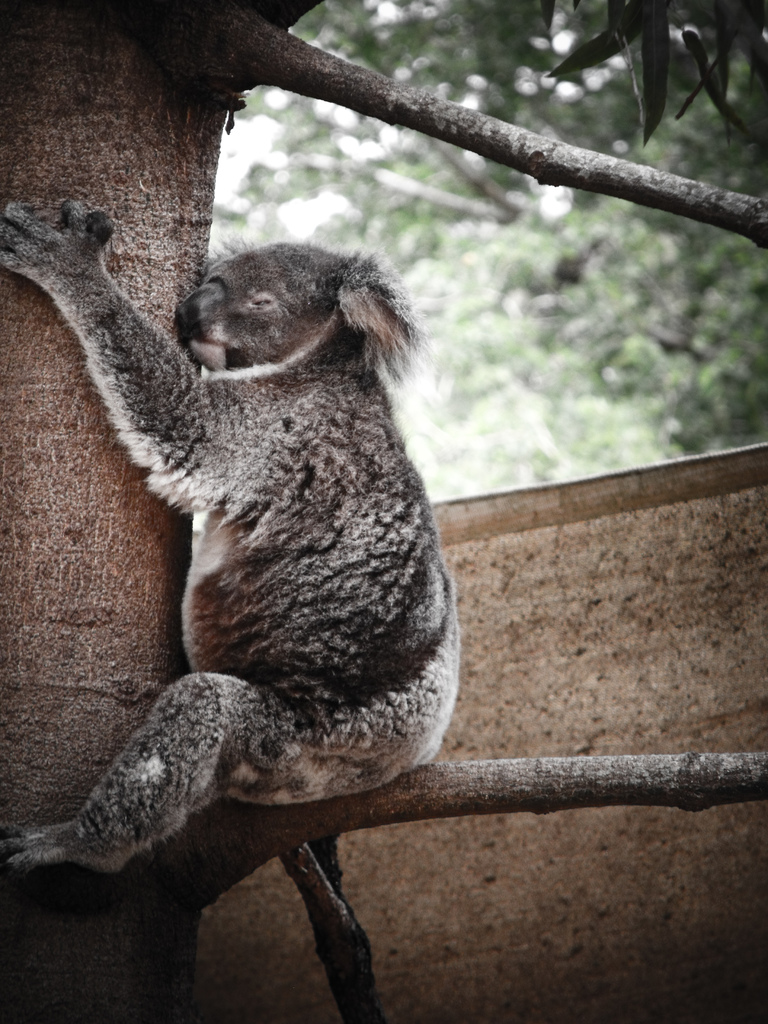

In [6]:
import os
import random
from pathlib import Path
from PIL import Image

# set seed
random.seed(42)

# Convert your original data_dir string to a path_object
base_dir = Path(train_dir)

# 1. Get all image paths 
image_path_list = list(base_dir.glob("*/*.jpg"))

# 2. Pick a random image
random_image_path = random.choice(image_path_list)

# 3. Get image class from directory name
image_class = os.path.basename(os.path.dirname(random_image_path))

# 4. Open image
img = Image.open(random_image_path)

# 5. Print metadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}") 
print(f"Image width: {img.width}")
print(f"Image mode: {img.mode}")

# Display the image
img

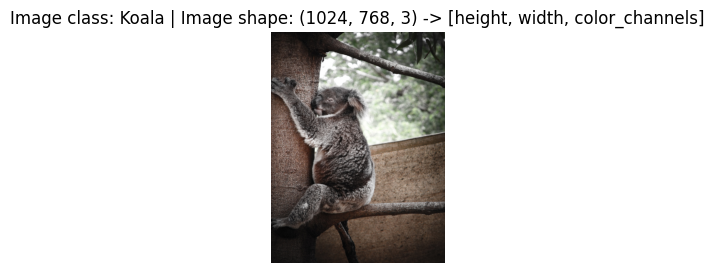

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Turn the image into an array
img_as_array = np.asarray(img)

# Plot the image with matplotlib
plt.figure(figsize=(4, 3))
plt.imshow(img_as_array)
plt.title(f"Image class: {image_class} | Image shape: {img_as_array.shape} -> [height, width, color_channels]")
plt.axis(False);

## Prétraitement 

Transforme les octets bruts des images en vecteurs mathématiques exploitables par les algorithmes de Machine Learning.

Une UDF (User Defined Function) Python utilise la bibliothèque PIL pour ouvrir le contenu binaire, redimensionner l'image à $32 \times 32$ pixels (pour alléger les calculs et éviter les plantages mémoire), puis la normaliser entre 0 et 1.Les pixels de l'image (en RVB) sont ensuite aplatis en un vecteur dense de $3072$ dimensions ($32 \times 32 \times 3$).

Chaque image est désormais convertie en un vecteur numérique propre stocké dans une colonne raw_features, filtrant au passage les éventuels fichiers corrompus.

In [8]:
import io
import numpy as np
from PIL import Image
from pyspark.sql.functions import udf
from pyspark.ml.linalg import Vectors, VectorUDT

def preprocess_image(content):
    try:
        img = Image.open(io.BytesIO(content)).convert("RGB")
        img = img.resize((32, 32)) # Réduit à 32x32 (3072 dimensions au lieu de 12288)
        arr = np.asarray(img, dtype=np.float32) / 255.0
        return Vectors.dense(arr.flatten())
    except Exception:
        return None

extract_features_udf = udf(preprocess_image, VectorUDT())

train_clean = train_df.withColumn("raw_features", extract_features_udf(col("content"))) \
    .filter(col("raw_features").isNotNull()) \
    .select("label_name", "raw_features")

test_clean = test_df.withColumn("raw_features", extract_features_udf(col("content"))) \
    .filter(col("raw_features").isNotNull()) \
    .select("label_name", "raw_features")

# Après avoir créé train_clean, mettez-le en cache
train_clean = train_clean.cache()
test_clean = test_clean.cache()

# Force une petite action pour charger le cache en mémoire une bonne fois pour toutes
print(f"Nombre d'images prêtes en cache : {train_clean.count()}")

Nombre d'images prêtes en cache : 13605


## Transformation 

Prépare mathématiquement et logiquement les données avant l'entraînement, tout en optimisant les performances de calcul de Spark.

StringIndexer convertit les noms textuels des animaux en indices numériques entiers (0, 1, 2...).
StandardScaler centre et réduit les valeurs des pixels pour uniformiser l'échelle des données et améliorer la convergence du modèle.
Le .cache() force Spark à conserver les données transformées en mémoire vive pour éviter de relire et recalculer les images à chaque étape suivante.

Le pipeline de transformation est appliqué et mis en cache. Les DataFrames possèdent désormais une colonne features normalisée et une colonne label numérique.

In [9]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, StandardScaler, PCA

# 1. Encodage des labels textuels en index numériques (0, 1, 2...)
label_indexer = StringIndexer(inputCol="label_name", outputCol="label", handleInvalid="keep")

# 2. Standardisation des vecteurs de pixels
scaler = StandardScaler(inputCol="raw_features", outputCol="scaled_features", withStd=True, withMean=True)

# 3. Réduction de dimension (PCA) pour compresser l'information des pixels
pca = PCA(k=100, inputCol="scaled_features", outputCol="features")

# Assemblage des étapes de transformation
transform_pipeline = Pipeline(stages=[label_indexer, scaler, pca])
transformer_model = transform_pipeline.fit(train_clean)

train_transformed = transformer_model.transform(train_clean)
test_transformed = transformer_model.transform(test_clean)

train_transformed.select("label_name", "label", "features").show(5)

+----------+-----+--------------------+
|label_name|label|            features|
+----------+-----+--------------------+
|    images|  0.0|[11.0723555218542...|
|    images|  0.0|[5.26881841964791...|
|    images|  0.0|[3.83200293325812...|
|    images|  0.0|[-24.803360185656...|
|    images|  0.0|[0.01397183369379...|
+----------+-----+--------------------+
only showing top 5 rows



26/11/18 21:49:26 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB


## ML 

Entraîne un modèle de classification robuste et distribué (RandomForestClassifier) sur les caractéristiques visuelles extraites.

Le modèle de Forêt Aléatoire est configuré pour lier la colonne de caractéristiques (features) à la classe cible (label).
Spark répartit l'apprentissage des arbres de décision sur les cœurs disponibles de la machine.

Le modèle apprend à reconnaître les motifs visuels de chaque animal. À la fin de cette cellule, on obtient un objet rf_model entraîné.


In [10]:
from pyspark.ml.classification import RandomForestClassifier

# Initialisation du modèle Random Forest distribué
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=100,
    maxDepth=10,
    seed=42
)

# Entraînement du modèle sur le cluster Spark
print("Entraînement du modèle en cours...")
rf_model = rf.fit(train_transformed)
print("Entraînement terminé !")

Entraînement du modèle en cours...


26/11/18 21:49:27 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/11/18 21:49:27 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/11/18 21:49:36 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/11/18 21:49:54 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB


Entraînement terminé !


## Éval 

Mesure la qualité et la fiabilité des prédictions du modèle sur le jeu de test indépendant.

Le modèle applique ses règles sur le jeu de test (test_transformed) pour générer des prédictions.
Le MulticlassClassificationEvaluator calcule deux métriques clés :
L'Accuracy (Précision globale) : Le pourcentage total de bonnes prédictions.
Le Score F1 : Une métrique plus fine qui équilibre la précision et le rappel, particulièrement utile si certaines classes d'animaux ont moins d'images.

On obtient des chiffres concrets sur les performances de votre classifieur, nous permettant de valider s'il est prêt pour la production ou s'il nécessite des ajustements.

In [11]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Génération des prédictions sur le jeu de test
predictions = rf_model.transform(test_transformed)

# Évaluateurs multiclasses
acc_evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
f1_evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")

accuracy = acc_evaluator.evaluate(predictions)
f1_score = f1_evaluator.evaluate(predictions)

print(f"Précision (Accuracy) sur le jeu de test : {accuracy * 100:.2f}%")
print(f"Score F1 pondéré : {f1_score:.4f}")

# Aperçu des prédictions vs réalité
predictions.select("label_name", "label", "prediction", "probability").show(10)

26/11/18 21:51:17 WARN DAGScheduler: Broadcasting large task binary with size 2.7 MiB
26/11/18 21:51:19 WARN DAGScheduler: Broadcasting large task binary with size 2.7 MiB
26/11/18 21:51:21 WARN DAGScheduler: Broadcasting large task binary with size 2.7 MiB


Précision (Accuracy) sur le jeu de test : 100.00%
Score F1 pondéré : 1.0000
+----------+-----+----------+-----------+
|label_name|label|prediction|probability|
+----------+-----+----------+-----------+
|    images|  0.0|       0.0|  [1.0,0.0]|
|    images|  0.0|       0.0|  [1.0,0.0]|
|    images|  0.0|       0.0|  [1.0,0.0]|
|    images|  0.0|       0.0|  [1.0,0.0]|
|    images|  0.0|       0.0|  [1.0,0.0]|
|    images|  0.0|       0.0|  [1.0,0.0]|
|    images|  0.0|       0.0|  [1.0,0.0]|
|    images|  0.0|       0.0|  [1.0,0.0]|
|    images|  0.0|       0.0|  [1.0,0.0]|
|    images|  0.0|       0.0|  [1.0,0.0]|
+----------+-----+----------+-----------+
only showing top 10 rows



## Déploiement 

Sécurise le travail réalisé en sauvegardant l'intégralité du pipeline et du modèle pour un usage ultérieur.

On regroupe les étapes de transformation et le modèle dans un Pipeline global que l'on sauvegarde sur le disque avec .save().
On simule un scénario de production en rechargeant le modèle (PipelineModel.load) et en utilisant IndexToString pour retraduire les prédictions numériques (ex: 1) en noms d'animaux compréhensibles par un utilisateur (ex: "Otter").

Notre pipeline est complètement opérationnel, exportable et prêt à être branché sur une application tierce (comme une API web) pour classifier de nouvelles images en temps réel.

In [12]:
from pyspark.ml import PipelineModel

# 1. Création d'un Pipeline complet (Transformation + Modèle ML)
full_pipeline = Pipeline(stages=[label_indexer, scaler, pca, rf])
full_model = full_pipeline.fit(train_clean)

# 2. Sauvegarde du modèle complet
model_save_path = "/kaggle/working/spark_wildlife_pipeline_model"
full_model.write().overwrite().save(model_save_path)
print(f"Pipeline sauvegardé avec succès dans : {model_save_path}")

# 3. Simulation du déploiement (Rechargement et prédiction sur une nouvelle image)
loaded_model = PipelineModel.load(model_save_path)

# Test d'inférence sur un échantillon
sample_new_data = test_clean.limit(3)
deployed_predictions = loaded_model.transform(sample_new_data)

# Conversion de l'index prédit vers le nom réel de l'animal
from pyspark.ml.feature import IndexToString
label_converter = IndexToString(
    inputCol="prediction", 
    outputCol="predicted_animal", 
    labels=loaded_model.stages[0].labels
)

final_output = label_converter.transform(deployed_predictions)
final_output.select("label_name", "predicted_animal").show()

26/11/18 21:54:57 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/11/18 21:54:57 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/11/18 21:55:04 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/11/18 21:55:20 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/11/18 21:55:38 WARN TaskSetManager: Stage 71 contains a task of very large size (2457 KiB). The maximum recommended task size is 1000 KiB.


Pipeline sauvegardé avec succès dans : /kaggle/working/spark_wildlife_pipeline_model


+----------+----------------+
|label_name|predicted_animal|
+----------+----------------+
|    images|          images|
|    images|          images|
|    images|          images|
+----------+----------------+



26/11/18 21:55:45 WARN DAGScheduler: Broadcasting large task binary with size 2.7 MiB
